# Finanzas cuantitativas paso a paso

Notebook de aprendizaje. Cada seccion tiene una explicacion teorica corta y codigo simple.

**Orden del notebook**

1. Datos y retornos
2. VaR historico, VaR parametrico y CVaR (pesos iguales)
3. Backtesting del VaR (test de Kupiec)
4. Pesos optimos (minima varianza y Sharpe maximo)
5. ARIMA y SARIMA
6. ARCH y GARCH (volatilidad que cambia en el tiempo)
7. Simulacion de Montecarlo
8. Black-Scholes y griegas
9. Backtesting de estrategias (cruce de medias)
10. Pairs trading
11. Modelos de Machine Learning: HMM y SGD
12. Paper trading

Regla de oro que se repite en todo el notebook: **nunca usar informacion del futuro** para tomar una decision hoy (look-ahead bias).

## 1. Datos y retornos

Descargamos precios de cierre ajustados (ya incluyen dividendos y splits).

**Retorno simple:** $r_t = \dfrac{P_t}{P_{t-1}} - 1$

**Retorno logaritmico:** $\ln r_t = \ln\dfrac{P_t}{P_{t-1}}$

Diferencias importantes:

| | Simple | Logaritmico |
|---|---|---|
| Suma en el tiempo | No (se compone) | Si: $\sum \ln r_t$ = retorno total |
| Suma entre activos (portafolio) | Si: $\sum w_i r_i$ | Solo aproximado |
| Uso tipico | Portafolio, VaR | Series de tiempo, GARCH, simulacion |

Para retornos diarios pequenos ambos son casi iguales porque $\ln(1+r) \approx r$.

Nota: se quito `SPCX` porque es un activo con poca historia. Al hacer `dropna()` habria recortado el historial de todos los demas.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm, chi2, jarque_bera
from scipy.optimize import minimize
from scipy.special import xlogy

plt.rcParams["figure.figsize"] = (10, 4)
np.random.seed(42)  # para que los resultados aleatorios sean reproducibles

tickers = ["META", "NVDA", "DBO", "SPY", "QQQ", "CEG", "SCHD"]
df = yf.download(tickers, period="5y", interval="1d", auto_adjust=True, progress=False)["Close"].dropna()
df.tail(3)

Ticker,CEG,DBO,META,NVDA,QQQ,SCHD,SPY
Date,,,,,,,
2026-11-18,262.739990,22.090000,616.380005,150.960007,659.510010,34.700001,730.200012
2026-11-19,252.029999,22.469999,596.219971,145.979996,645.039978,34.200001,715.869995
2026-11-20,243.919998,22.410000,569.210022,136.065002,621.479980,34.327599,700.809998


In [2]:
ret = df.pct_change().dropna()            # retornos simples
lret = np.log(df / df.shift(1)).dropna()  # retornos logaritmicos

# Estadisticas basicas por activo (retornos diarios)
stats = pd.DataFrame({
    "media diaria %": ret.mean() * 100,
    "volatilidad diaria %": ret.std() * 100,
    "volatilidad anual %": ret.std() * np.sqrt(252) * 100,  # raiz de 252 dias de mercado
    "skewness": ret.skew(),                                 # asimetria (0 en una normal)
    "kurtosis exceso": ret.kurt(),                          # colas pesadas (0 en una normal)
    "p-valor Jarque-Bera": [jarque_bera(ret[c])[1] for c in ret.columns],
})
stats.round(3)

,media diaria %,volatilidad diaria %,volatilidad anual %,skewness,kurtosis exceso,p-valor Jarque-Bera
Ticker,,,,,,
CEG,0.196,3.107,49.316,0.710,9.607,0.0
DBO,0.068,2.142,33.997,-0.219,1.927,0.0
META,0.090,2.891,45.888,-0.088,17.529,0.0
NVDA,0.192,3.257,51.706,0.521,4.830,0.0
QQQ,0.057,1.478,23.456,0.120,4.850,0.0
SCHD,0.039,0.917,14.561,0.001,3.881,0.0
SPY,0.047,1.097,17.412,0.285,8.943,0.0


**Lectura:** una kurtosis en exceso mayor que 0 indica colas pesadas: ocurren movimientos extremos con mas frecuencia que en una normal.
Un p-valor de Jarque-Bera menor que 0.05 rechaza la normalidad. Esto es importante porque el VaR parametrico **asume normalidad** y probablemente subestima el riesgo.

## 2. VaR historico, VaR parametrico y CVaR

El **VaR** (Value at Risk) responde: *con una confianza del 95%, cual es la maxima perdida esperada en un dia?*

Para un portafolio con pesos $w$ y retornos simples de cada activo, el retorno del portafolio es:

$$r_p = \sum_i w_i r_i$$

Con pesos iguales: $w_i = 1/n$.

**VaR historico:** el percentil de la distribucion real de retornos. No supone ninguna distribucion.

$$VaR_{\alpha} = -\text{percentil}(r_p,\ \alpha)$$

**VaR parametrico:** supone que $r_p \sim N(\mu, \sigma^2)$.

$$VaR_{\alpha} = -(\mu + z_{\alpha}\,\sigma), \qquad z_{0.05} = -1.645,\quad z_{0.01} = -2.326$$

**CVaR (Expected Shortfall):** la perdida promedio **cuando ya se supero el VaR**. Es mas informativo porque mide la cola.

$$CVaR_{\alpha} = -E[r_p \mid r_p \le -VaR_{\alpha}]$$

Para la normal: $CVaR_{\alpha} = -\left(\mu - \sigma\,\dfrac{\varphi(z_{\alpha})}{\alpha}\right)$, donde $\varphi$ es la densidad normal estandar.

Se cumple siempre: **CVaR >= VaR**, y VaR 99% >= VaR 95%.

In [3]:
n = len(tickers)
w = np.ones(n) / n        # pesos iguales: 1/n cada activo
V = 10_000                # valor total del portafolio en USD (cambialo a tu monto)
rp = ret @ w              # serie de retornos diarios del portafolio

def var_cvar(r, conf):
    """Devuelve VaR hist, VaR param, CVaR hist, CVaR param (como fraccion positiva)."""
    a = 1 - conf
    # Historico
    var_h = -np.percentile(r, a * 100)
    cvar_h = -r[r <= -var_h].mean()
    # Parametrico (normal)
    mu, sd = r.mean(), r.std()
    z = norm.ppf(a)
    var_p = -(mu + z * sd)
    cvar_p = -(mu - sd * norm.pdf(z) / a)
    return var_h, var_p, cvar_h, cvar_p

filas = []
for conf in (0.95, 0.99):
    vh, vp, ch, cp = var_cvar(rp, conf)
    filas.append([f"{conf:.0%}", vh, vp, ch, cp])

tabla = pd.DataFrame(filas, columns=["confianza", "VaR hist", "VaR param", "CVaR hist", "CVaR param"]).set_index("confianza")
print("Portafolio con pesos iguales, horizonte 1 dia (% del portafolio)")
print((tabla * 100).round(2))
print("\nEn dolares sobre", V, "USD")
print((tabla * V).round(0))

Portafolio con pesos iguales, horizonte 1 dia (% del portafolio)
           VaR hist  VaR param  CVaR hist  CVaR param
confianza                                            
95%            2.12       2.27       3.23        2.87
99%            3.84       3.25       4.95        3.73

En dolares sobre 10000 USD
           VaR hist  VaR param  CVaR hist  CVaR param
confianza                                            
95%           212.0      227.0      323.0       287.0
99%           384.0      325.0      495.0       373.0


In [4]:
# VaR de cada activo por separado al 95% (para comparar con el portafolio)
por_activo = pd.DataFrame(
    {c: var_cvar(ret[c], 0.95) for c in ret.columns},
    index=["VaR hist", "VaR param", "CVaR hist", "CVaR param"],
).T
por_activo.loc["PORTAFOLIO"] = var_cvar(rp, 0.95)
print((por_activo * 100).round(2))

            VaR hist  VaR param  CVaR hist  CVaR param
CEG             4.37       4.91       6.69        6.21
DBO             3.47       3.46       4.95        4.35
META            4.05       4.66       6.29        5.87
NVDA            4.83       5.17       6.77        6.53
QQQ             2.37       2.37       3.38        2.99
SCHD            1.43       1.47       2.03        1.85
SPY             1.68       1.76       2.53        2.22
PORTAFOLIO      2.12       2.27       3.23        2.87


**Diversificacion:** el VaR del portafolio es menor que el promedio de los VaR individuales porque los activos no caen todos a la vez (correlacion menor que 1).
Sumar los VaR individuales **sobreestima** el riesgo.

**Verificacion por matrices:** la volatilidad del portafolio tambien se calcula con la covarianza:

$$\sigma_p = \sqrt{w^T \Sigma\, w}$$

In [5]:
cov = ret.cov()
sigma_p_matriz = np.sqrt(w @ cov.values @ w)
print("sigma del portafolio con la formula matricial:", round(sigma_p_matriz, 6))
print("sigma del portafolio directo de la serie     :", round(rp.std(), 6))

# Escalado a varios dias (solo valido bajo supuestos de normalidad e independencia)
for dias in (1, 5, 10):
    print(f"VaR parametrico 99% a {dias} dias: {var_cvar(rp, 0.99)[1] * np.sqrt(dias):.2%}")

sigma del portafolio con la formula matricial: 0.014378
sigma del portafolio directo de la serie     : 0.014378
VaR parametrico 99% a 1 dias: 3.25%
VaR parametrico 99% a 5 dias: 7.26%
VaR parametrico 99% a 10 dias: 10.27%


La raiz del tiempo ($\sqrt{T}$) escala la **volatilidad**, no el VaR directamente. El VaR a $T$ dias es aproximadamente $\sigma\sqrt{T}$ por el cuantil, y el termino de la media crece con $T$ (no con $\sqrt{T}$). Para un aprendizaje basico se ignora la media por ser muy pequena.

## 3. Backtesting del VaR (test de Kupiec)

Un modelo de VaR solo sirve si es correcto. Contamos las **excepciones**: dias en que la perdida real fue mayor que el VaR estimado.

Con confianza 95% esperamos un 5% de excepciones. Si hay muchas mas, el modelo subestima el riesgo. Si hay muchas menos, es demasiado conservador.

**Test de Kupiec (proportion of failures):** contrasta si la tasa de excepciones observada $x/N$ es igual a la esperada $p$.

$$LR = -2\ln\left[\frac{(1-p)^{N-x}\,p^x}{(1-x/N)^{N-x}\,(x/N)^x}\right] \sim \chi^2_1$$

Si el p-valor es menor que 0.05, se rechaza el modelo.

Para no usar informacion futura, el VaR de cada dia se calcula con una **ventana movil** de 250 dias y se desplaza un dia (`shift(1)`).

Dias evaluados: 965 | Excepciones: 47 (4.87%) | Esperadas: 5%
Kupiec LR = 0.034, p-valor = 0.853 -> modelo aceptable


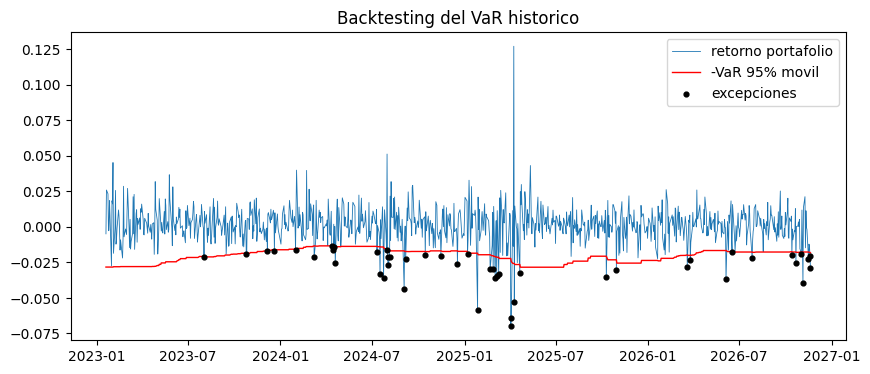

In [6]:
ventana = 250
p = 0.05  # 1 - 95%

# VaR historico movil: usa solo datos pasados
var_movil = -rp.rolling(ventana).quantile(p).shift(1)
valido = var_movil.notna()
excep = (rp < -var_movil)[valido]

N, x = len(excep), int(excep.sum())

def kupiec(x, N, p):
    pi = x / N
    ll_h0 = xlogy(N - x, 1 - p) + xlogy(x, p)      # verosimilitud si la tasa real es p
    ll_h1 = xlogy(N - x, 1 - pi) + xlogy(x, pi)    # verosimilitud con la tasa observada
    lr = -2 * (ll_h0 - ll_h1)
    return lr, 1 - chi2.cdf(lr, 1)

lr, pval = kupiec(x, N, p)
print(f"Dias evaluados: {N} | Excepciones: {x} ({x/N:.2%}) | Esperadas: {p:.0%}")
print(f"Kupiec LR = {lr:.3f}, p-valor = {pval:.3f} ->", "modelo aceptable" if pval > 0.05 else "modelo rechazado")

plt.plot(rp[valido], lw=0.6, label="retorno portafolio")
plt.plot(-var_movil[valido], color="red", lw=1, label="-VaR 95% movil")
plt.scatter(excep[excep].index, rp[valido][excep], color="black", s=12, label="excepciones", zorder=3)
plt.legend(); plt.title("Backtesting del VaR historico"); plt.show()

## 4. Pesos optimos (teoria de Markowitz)

Retorno esperado del portafolio: $\mu_p = w^T\mu$. Riesgo: $\sigma_p = \sqrt{w^T\Sigma w}$.

Dos portafolios clasicos:

- **Minima varianza:** minimiza $\sigma_p$ sin importar el retorno.
- **Sharpe maximo:** maximiza $\dfrac{\mu_p - r_f}{\sigma_p}$ (retorno por unidad de riesgo).

Restricciones: $\sum w_i = 1$ y $0 \le w_i \le 1$ (sin ventas en corto).

Se anualizan los retornos: la media por 252 y la covarianza por 252.

**Advertencia:** los pesos optimos usan la media historica, que es muy ruidosa. Los resultados son muy sensibles y funcionan peor fuera de muestra de lo que parecen. Por eso este ejercicio es para entender la teoria, no para invertir con esos pesos.

In [7]:
mu_a = ret.mean().values * 252
cov_a = ret.cov().values * 252
rf = 0.0   # tasa libre de riesgo (simplificacion)

def vol_p(w):      return np.sqrt(w @ cov_a @ w)
def ret_p(w):      return w @ mu_a
def neg_sharpe(w): return -(ret_p(w) - rf) / vol_p(w)

restr = {"type": "eq", "fun": lambda w: w.sum() - 1}
limites = [(0, 1)] * n
w0 = np.ones(n) / n

w_minvar = minimize(vol_p, w0, bounds=limites, constraints=restr).x
w_sharpe = minimize(neg_sharpe, w0, bounds=limites, constraints=restr).x

pesos = pd.DataFrame({"iguales": w, "min varianza": w_minvar, "Sharpe max": w_sharpe}, index=tickers)
print((pesos * 100).round(1))

resumen = pd.DataFrame(
    {nombre: [ret_p(wi), vol_p(wi), (ret_p(wi) - rf) / vol_p(wi), var_cvar(ret @ wi, 0.95)[0]]
     for nombre, wi in pesos.items()},
    index=["retorno anual", "volatilidad anual", "Sharpe", "VaR hist 95% diario"],
).T
print()
print(resumen.round(4))

      iguales  min varianza  Sharpe max
META     14.3           0.0        25.3
NVDA     14.3          11.1        18.1
DBO      14.3           0.0         0.0
SPY      14.3           0.0        20.1
QQQ      14.3           0.0         0.0
CEG      14.3          71.2        36.5
SCHD     14.3          17.8         0.0

              retorno anual  volatilidad anual  Sharpe  VaR hist 95% diario
iguales              0.2482             0.2282  1.0873               0.0212
min varianza         0.1104             0.1391  0.7932               0.0346
Sharpe max           0.2889             0.2289  1.2623               0.0307


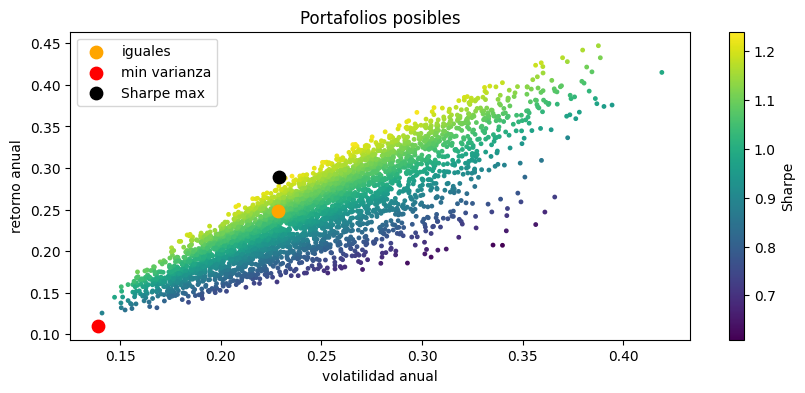

In [8]:
# Frontera eficiente aproximada: miles de portafolios con pesos aleatorios
aleatorios = np.random.dirichlet(np.ones(n), 4000)   # pesos que suman 1 y son positivos
r_al = aleatorios @ mu_a
v_al = np.sqrt(np.einsum("ij,jk,ik->i", aleatorios, cov_a, aleatorios))

plt.scatter(v_al, r_al, c=r_al / v_al, cmap="viridis", s=6)
plt.colorbar(label="Sharpe")
plt.scatter(vol_p(w), ret_p(w), color="orange", s=80, label="iguales")
plt.scatter(vol_p(w_minvar), ret_p(w_minvar), color="red", s=80, label="min varianza")
plt.scatter(vol_p(w_sharpe), ret_p(w_sharpe), color="black", s=80, label="Sharpe max")
plt.xlabel("volatilidad anual"); plt.ylabel("retorno anual"); plt.legend()
plt.title("Portafolios posibles"); plt.show()

## 5. ARIMA y SARIMA

Modelos para **predecir la media** de una serie de tiempo.

**Antes de modelar: estacionariedad.** ARIMA necesita una serie estacionaria (media y varianza constantes en el tiempo). Los precios no lo son; los retornos casi siempre si.
Se verifica con la prueba **ADF** (Augmented Dickey-Fuller): hipotesis nula = la serie tiene raiz unitaria (no estacionaria). p-valor menor que 0.05 permite rechazarla.

**ARIMA(p, d, q):**

- **AR(p):** hoy depende de los ultimos $p$ valores: $y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$
- **I(d):** cuantas veces se diferencia la serie para hacerla estacionaria. Usar retornos ya equivale a $d=1$ sobre el log-precio.
- **MA(q):** hoy depende de los ultimos $q$ errores: $y_t = c + \varepsilon_t + \theta_1\varepsilon_{t-1} + \dots$

**Como elegir p y q:** ACF y PACF como guia, y criterios de informacion (AIC, BIC): menor es mejor. BIC penaliza mas la complejidad.

**SARIMA(p,d,q)(P,D,Q,s):** agrega componentes estacionales con periodo $s$ (por ejemplo $s=12$ en datos mensuales).

Expectativa realista: los retornos diarios son casi impredecibles (mercado casi eficiente), asi que el R2 sera cercano a 0. El valor de este ejercicio es aprender la mecanica.

ADF sobre log-precio  -> p-valor: 0.9009 (no estacionaria si > 0.05)
ADF sobre retornos log -> p-valor: 0.0 (estacionaria si < 0.05)


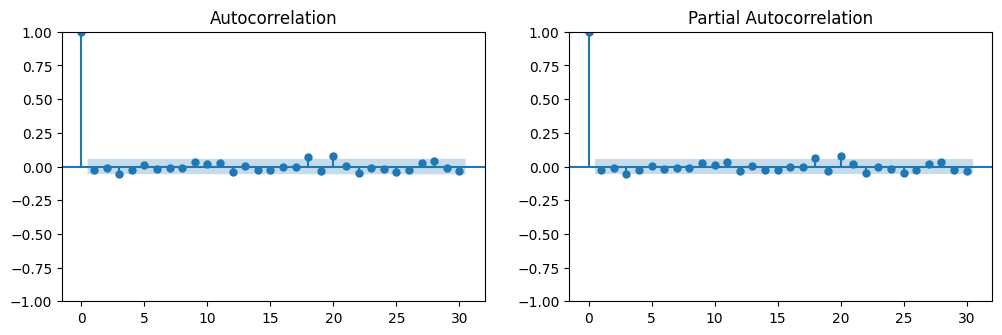

In [9]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

y = lret["SPY"].reset_index(drop=True)   # retornos log de SPY (indice numerico para evitar avisos de frecuencia)
log_precio = np.log(df["SPY"]).reset_index(drop=True)

print("ADF sobre log-precio  -> p-valor:", round(adfuller(log_precio)[1], 4), "(no estacionaria si > 0.05)")
print("ADF sobre retornos log -> p-valor:", round(adfuller(y)[1], 4), "(estacionaria si < 0.05)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(y, lags=30, ax=ax[0]); plot_pacf(y, lags=30, ax=ax[1])
plt.show()

In [10]:
# Busqueda simple de p y q (0 a 2) por AIC y BIC
resultados = []
for p_ in range(3):
    for q_ in range(3):
        m = ARIMA(y, order=(p_, 0, q_)).fit()
        resultados.append((p_, q_, m.aic, m.bic))

tab = pd.DataFrame(resultados, columns=["p", "q", "AIC", "BIC"]).sort_values("BIC")
print(tab.head(5).round(1))

mejor = tab.iloc[0]
modelo = ARIMA(y, order=(int(mejor.p), 0, int(mejor.q))).fit()
print(modelo.summary().tables[1])
print("\nPronostico de los proximos 5 retornos diarios (%):")
print((modelo.forecast(5) * 100).round(4).values)

   p  q     AIC     BIC
0  0  0 -7518.3 -7508.1
1  0  1 -7517.2 -7501.9
3  1  0 -7517.1 -7501.8
2  0  2 -7515.5 -7495.1
6  2  0 -7515.4 -7495.0


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      1.300      0.194      -0.000       0.001
sigma2         0.0001   2.19e-06     54.799      0.000       0.000       0.000

Pronostico de los proximos 5 retornos diarios (%):
[0.0409 0.0409 0.0409 0.0409 0.0409]


In [11]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Diagnostico: si el modelo captura la estructura, los residuos no deben tener autocorrelacion
res = modelo.resid
lb = acorr_ljungbox(res, lags=[10])
lb2 = acorr_ljungbox(res ** 2, lags=[10])
print("Ljung-Box residuos      p-valor:", round(float(lb["lb_pvalue"].iloc[0]), 4))
print("Ljung-Box residuos^2    p-valor:", round(float(lb2["lb_pvalue"].iloc[0]), 4))
print("Test ARCH (LM)          p-valor:", round(het_arch(res)[1], 4))

Ljung-Box residuos      p-valor: 0.6426
Ljung-Box residuos^2    p-valor: 0.0
Test ARCH (LM)          p-valor: 0.0


**Lectura importante:** es comun que los residuos tengan poca autocorrelacion (p-valor alto) pero que los **residuos al cuadrado** si tengan (p-valor bajo). Eso significa que la **media** es casi impredecible, pero la **varianza** si tiene estructura: periodos tranquilos y periodos turbulentos se agrupan (volatility clustering). Esto motiva la siguiente seccion (GARCH).

### SARIMA con datos mensuales

La estacionalidad (efectos de calendario) casi no existe en retornos diarios. La probamos con retornos **mensuales**, con $s=12$.

In [12]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

spy_m = yf.download("SPY", period="15y", interval="1mo", auto_adjust=True, progress=False)["Close"].squeeze()
rm = np.log(spy_m).diff().dropna().reset_index(drop=True)

arima_m = ARIMA(rm, order=(1, 0, 1)).fit()
sarima_m = SARIMAX(rm, order=(1, 0, 1), seasonal_order=(1, 0, 1, 12)).fit(disp=False)

print("ARIMA(1,0,1)           AIC:", round(arima_m.aic, 1), "BIC:", round(arima_m.bic, 1))
print("SARIMA(1,0,1)(1,0,1,12) AIC:", round(sarima_m.aic, 1), "BIC:", round(sarima_m.bic, 1))
print("\nPronostico SARIMA de los proximos 3 meses (%):", (sarima_m.forecast(3) * 100).round(2).values)

ARIMA(1,0,1)           AIC: -639.8 BIC: -627.0
SARIMA(1,0,1)(1,0,1,12) AIC: -622.9 BIC: -607.0

Pronostico SARIMA de los proximos 3 meses (%): [1.22 0.76 0.19]


C:\Users\jorch\AppData\Roaming\Python\Python313\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Si el AIC/BIC del SARIMA no mejora claramente frente al ARIMA, la estacionalidad no aporta y el modelo mas simple es preferible (principio de parsimonia).

## 6. ARCH y GARCH: modelar la volatilidad

En finanzas la volatilidad **no es constante**: hay rachas de calma y de crisis. ARCH y GARCH modelan la varianza condicional $\sigma_t^2$.

**ARCH(1)** (Engle): la varianza de hoy depende del shock de ayer.

$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2$$

**GARCH(1,1)** (Bollerslev): agrega la varianza de ayer. Es el modelo estandar.

$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

- $\alpha$: reaccion a shocks recientes.
- $\beta$: persistencia de la volatilidad.
- $\alpha + \beta$ cercano a 1 significa que los choques de volatilidad tardan mucho en desaparecer. Debe ser menor que 1 para que el modelo sea estable.

**GJR-GARCH:** agrega un termino $\gamma$ para que las caidas aumenten mas la volatilidad que las subidas (efecto apalancamiento).

Se usa distribucion **t de Student** porque tiene colas mas pesadas que la normal.

Convencion de la libreria `arch`: se trabaja con retornos multiplicados por 100 (en porcentaje) para que la optimizacion converja mejor.

In [13]:
from arch import arch_model

r = lret["SPY"] * 100

m_arch = arch_model(r, mean="Constant", vol="ARCH", p=1, dist="normal").fit(disp="off")
m_garch = arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
m_gjr = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")

comparacion = pd.DataFrame({
    "AIC": [m_arch.aic, m_garch.aic, m_gjr.aic],
    "BIC": [m_arch.bic, m_garch.bic, m_gjr.bic],
}, index=["ARCH(1)", "GARCH(1,1)-t", "GJR-GARCH-t"])
print(comparacion.round(1))

print("\nParametros GARCH(1,1):")
print(m_garch.params.round(4))
print("Persistencia alpha + beta =", round(m_garch.params["alpha[1]"] + m_garch.params["beta[1]"], 4))
print("\nParametros GJR-GARCH (gamma > 0 indica efecto apalancamiento):")
print(m_gjr.params.round(4))

                 AIC     BIC
ARCH(1)       3579.0  3594.3
GARCH(1,1)-t  3323.4  3348.9
GJR-GARCH-t   3277.5  3308.1

Parametros GARCH(1,1):
mu          0.0971
omega       0.0254
alpha[1]    0.1022
beta[1]     0.8784
nu          6.6076
Name: params, dtype: float64
Persistencia alpha + beta = 0.9806

Parametros GJR-GARCH (gamma > 0 indica efecto apalancamiento):
mu          0.0698
omega       0.0227
alpha[1]    0.0000
gamma[1]    0.1660
beta[1]     0.8934
nu          7.6411
Name: params, dtype: float64


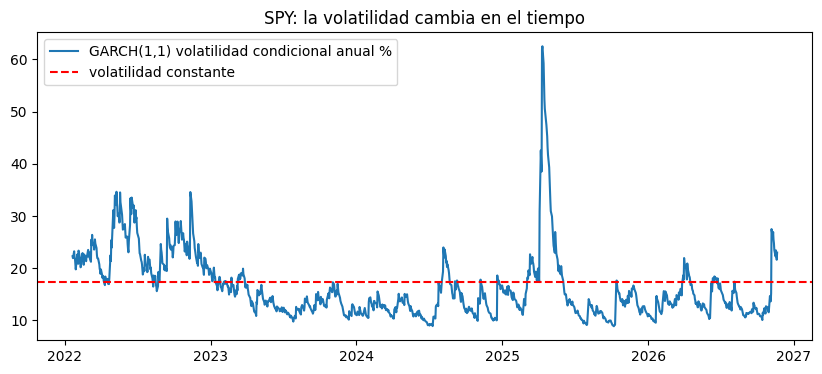

In [14]:
# Volatilidad condicional anualizada vs volatilidad constante
vol_cond = m_garch.conditional_volatility * np.sqrt(252)
plt.plot(df.index[1:], vol_cond.values, label="GARCH(1,1) volatilidad condicional anual %")
plt.axhline(r.std() * np.sqrt(252), color="red", ls="--", label="volatilidad constante")
plt.legend(); plt.title("SPY: la volatilidad cambia en el tiempo"); plt.show()

### VaR con GARCH (simulacion historica filtrada)

1. GARCH pronostica la volatilidad de **manana**, $\sigma_{t+1}$.
2. Se toman los residuos estandarizados $z_t = \varepsilon_t/\sigma_t$ (aproximadamente iid) y se obtiene su percentil 5%.
3. $VaR = -(\mu + \sigma_{t+1}\cdot q_{5\%})$

Ventaja: si hoy el mercado esta turbulento, el VaR sube automaticamente; el VaR con volatilidad constante no lo hace.

In [15]:
sigma_manana = np.sqrt(m_garch.forecast(horizon=1).variance.iloc[-1, 0])  # en %
mu_g = m_garch.params["mu"]
q05 = np.percentile(m_garch.std_resid.dropna(), 5)

var_garch = -(mu_g + sigma_manana * q05) / 100
var_const = -(r.mean() + norm.ppf(0.05) * r.std()) / 100

print(f"Volatilidad pronosticada para manana (anual): {sigma_manana * np.sqrt(252):.1f}%")
print(f"VaR 95% 1 dia SPY con GARCH            : {var_garch:.2%}")
print(f"VaR 95% 1 dia SPY con volatilidad const: {var_const:.2%}")

Volatilidad pronosticada para manana (anual): 24.5%
VaR 95% 1 dia SPY con GARCH            : 2.64%
VaR 95% 1 dia SPY con volatilidad const: 1.76%


## 7. Simulacion de Montecarlo

Idea: en lugar de usar solo el pasado, **simulamos miles de futuros posibles** con un modelo y miramos la distribucion.

### 7.1 VaR de Montecarlo con activos correlacionados

1. Estimar el vector de medias $\mu$ y la covarianza $\Sigma$ de los retornos log.
2. Descomposicion de Cholesky: $\Sigma = L L^T$.
3. Generar $Z \sim N(0, I)$ independientes y construir retornos correlacionados: $r = \mu + L Z$.
4. Convertir a retorno simple, $e^{r}-1$, calcular el retorno del portafolio y su percentil.

Cholesky es lo que introduce la correlacion entre activos.

95%  VaR MC: 2.25%   CVaR MC: 2.84%
99%  VaR MC: 3.21%   CVaR MC: 3.71%


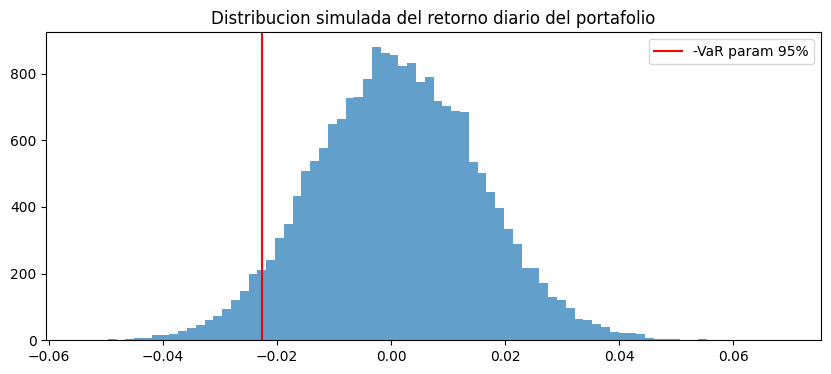

In [16]:
mu_d = lret.mean().values
cov_d = lret.cov().values
L = np.linalg.cholesky(cov_d)

n_sim = 20_000
Z = np.random.standard_normal((n_sim, n))     # normales independientes
sim_log = mu_d + Z @ L.T                      # retornos log correlacionados
sim_simple = np.exp(sim_log) - 1              # a retornos simples para el portafolio
sim_rp = sim_simple @ w                       # portafolio con pesos iguales

for conf in (0.95, 0.99):
    var_mc = -np.percentile(sim_rp, (1 - conf) * 100)
    cvar_mc = -sim_rp[sim_rp <= -var_mc].mean()
    print(f"{conf:.0%}  VaR MC: {var_mc:.2%}   CVaR MC: {cvar_mc:.2%}")

plt.hist(sim_rp, bins=80, alpha=0.7)
plt.axvline(-var_cvar(rp, 0.95)[1], color="red", label="-VaR param 95%")
plt.title("Distribucion simulada del retorno diario del portafolio"); plt.legend(); plt.show()

### 7.2 Trayectorias de precio (Movimiento Browniano Geometrico)

Modelo de precios: $S_{t+1} = S_t \exp\left[(\mu - \tfrac{1}{2}\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,Z\right]$

El termino $(\mu - \tfrac12\sigma^2)$ es exactamente la **media del retorno logaritmico**. Por eso usamos directamente la media y desviacion de los retornos log: no hace falta restar $\tfrac12\sigma^2$ otra vez.

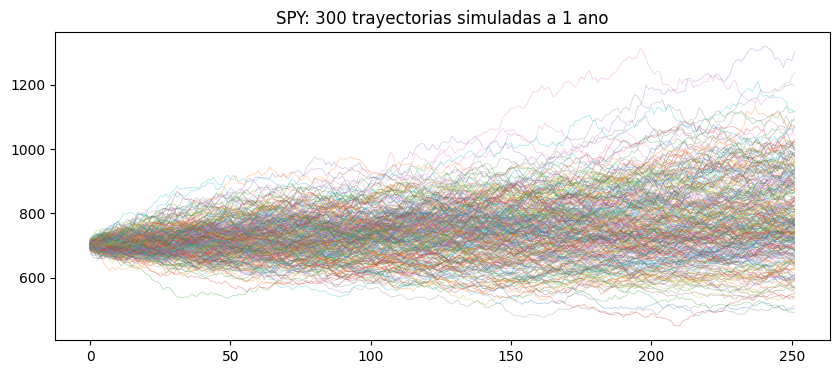

Precio actual: 700.81
Mediana final: 774.37
Percentil 5% : 590.71   Percentil 95%: 1013.31
Probabilidad de terminar por debajo del precio actual: 25.7%


In [17]:
S0 = df["SPY"].iloc[-1]
m_l = lret["SPY"].mean()     # media diaria del log-retorno (ya incluye -0.5*sigma^2)
s_l = lret["SPY"].std()

dias, trayectorias = 252, 300
Z = np.random.standard_normal((dias, trayectorias))
incrementos = m_l + s_l * Z
paths = S0 * np.exp(np.cumsum(incrementos, axis=0))

plt.plot(paths, lw=0.5, alpha=0.4)
plt.title("SPY: 300 trayectorias simuladas a 1 ano"); plt.show()

final = paths[-1]
print(f"Precio actual: {S0:.2f}")
print(f"Mediana final: {np.median(final):.2f}")
print(f"Percentil 5% : {np.percentile(final, 5):.2f}   Percentil 95%: {np.percentile(final, 95):.2f}")
print(f"Probabilidad de terminar por debajo del precio actual: {(final < S0).mean():.1%}")

## 8. Black-Scholes y griegas

Valoracion de opciones europeas bajo estos supuestos: precio log-normal, volatilidad y tasa constantes, sin dividendos.

$$d_1 = \frac{\ln(S/K) + (r + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

$$C = S\,N(d_1) - K e^{-rT} N(d_2) \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)$$

**Griegas** (sensibilidades del precio de la opcion):

| Griega | Mide | Formula (call) |
|---|---|---|
| Delta | cambio por $1 del subyacente | $N(d_1)$ |
| Gamma | cambio de delta | $\varphi(d_1)/(S\sigma\sqrt{T})$ |
| Vega | cambio por 1.00 de volatilidad | $S\varphi(d_1)\sqrt{T}$ |
| Theta | perdida por paso del tiempo | $-\dfrac{S\varphi(d_1)\sigma}{2\sqrt{T}} - rKe^{-rT}N(d_2)$ |

**Paridad put-call (relacion de no arbitraje):** $C - P = S - K e^{-rT}$. Si en el mercado no se cumple, hay una oportunidad de arbitraje (en la practica los costos y spreads suelen eliminarla).

**Volatilidad implicita:** la $\sigma$ que hace que el precio del modelo iguale al precio del mercado. Se despeja numericamente porque no hay formula cerrada.

**Idea de arbitraje de volatilidad:** si la volatilidad implicita es mucho mayor que la realizada esperada, la opcion esta "cara" (se vende volatilidad); si es menor, esta "barata". Black-Scholes sirve de **referencia** para comparar, no es por si mismo una estrategia.

In [18]:
from scipy.optimize import brentq

def d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)

def bs_call(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def bs_put(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def griegas_call(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return {
        "delta": norm.cdf(d1),
        "gamma": norm.pdf(d1) / (S * sigma * np.sqrt(T)),
        "vega (por 1 punto de vol)": S * norm.pdf(d1) * np.sqrt(T) / 100,
        "theta (por dia)": (-S * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2)) / 365,
    }

def vol_implicita(precio_mercado, S, K, T, r):
    return brentq(lambda s: bs_call(S, K, T, r, s) - precio_mercado, 1e-4, 5)

# Ejemplo con SPY: opcion call at-the-money a 3 meses
S = df["SPY"].iloc[-1]
K, T, r_libre = S, 0.25, 0.04
sigma_real = lret["SPY"].std() * np.sqrt(252)   # volatilidad realizada anual

c = bs_call(S, K, T, r_libre, sigma_real)
pt = bs_put(S, K, T, r_libre, sigma_real)
print(f"S = {S:.2f}  K = {K:.2f}  T = {T}  r = {r_libre}  sigma realizada = {sigma_real:.2%}")
print(f"Call = {c:.2f}   Put = {pt:.2f}")
print(f"Paridad put-call: C - P = {c - pt:.4f}   S - K*exp(-rT) = {S - K * np.exp(-r_libre * T):.4f}")
print("Griegas del call:", {k: round(v, 4) for k, v in griegas_call(S, K, T, r_libre, sigma_real).items()})

# Ejemplo ilustrativo (precio inventado): el mercado cotiza el call 10% mas caro que el modelo
precio_mercado = c * 1.10
iv = vol_implicita(precio_mercado, S, K, T, r_libre)
print(f"\nSi el mercado cotiza {precio_mercado:.2f}, la vol implicita es {iv:.2%} vs realizada {sigma_real:.2%}")

S = 700.81  K = 700.81  T = 0.25  r = 0.04  sigma realizada = 17.39%
Call = 27.82   Put = 20.85
Paridad put-call: C - P = 6.9732   S - K*exp(-rT) = 6.9732
Griegas del call: {'delta': np.float64(0.563), 'gamma': np.float64(0.0065), 'vega (por 1 punto de vol)': np.float64(1.3805), 'theta (por dia)': np.float64(-0.1717)}

Si el mercado cotiza 30.61, la vol implicita es 19.40% vs realizada 17.39%


### Verificacion con Montecarlo

Bajo la medida neutral al riesgo el precio es el valor esperado descontado del pago. Se simula $S_T = S\exp[(r-\tfrac12\sigma^2)T + \sigma\sqrt{T}Z]$ (se usa $r$ y **no** $\mu$) y se promedia $\max(S_T-K, 0)$.
El resultado debe acercarse al precio de Black-Scholes.

In [19]:
Z = np.random.standard_normal(500_000)
ST = S * np.exp((r_libre - 0.5 * sigma_real ** 2) * T + sigma_real * np.sqrt(T) * Z)
call_mc = np.exp(-r_libre * T) * np.maximum(ST - K, 0).mean()
print(f"Call Black-Scholes: {c:.4f}   Call Montecarlo: {call_mc:.4f}")

Call Black-Scholes: 27.8240   Call Montecarlo: 27.8071


## 9. Backtesting de estrategias

Probar una estrategia con datos historicos. Reglas para que sea honesto:

1. **Evitar look-ahead:** la senal calculada con el cierre de hoy solo se puede operar **manana**. Por eso se usa `shift(1)`.
2. **Costos de transaccion:** cada cambio de posicion cuesta (comision + spread).
3. **Separar muestra de entrenamiento y de prueba** si se ajustan parametros.
4. Evaluar con varias metricas, no solo el retorno.

**Metricas:**

- Retorno anualizado y volatilidad anual.
- **Sharpe** = media / desviacion de los retornos diarios x $\sqrt{252}$.
- **Maximo drawdown:** la peor caida desde un maximo previo.

### Ejemplo: cruce de medias moviles en SPY

Posicion larga cuando la media rapida (20 dias) esta por encima de la lenta (100 dias); si no, en efectivo.

               estrategia  comprar y mantener
retorno anual       0.080               0.149
volatilidad         0.120               0.166
Sharpe              0.700               0.924
max drawdown       -0.158              -0.188


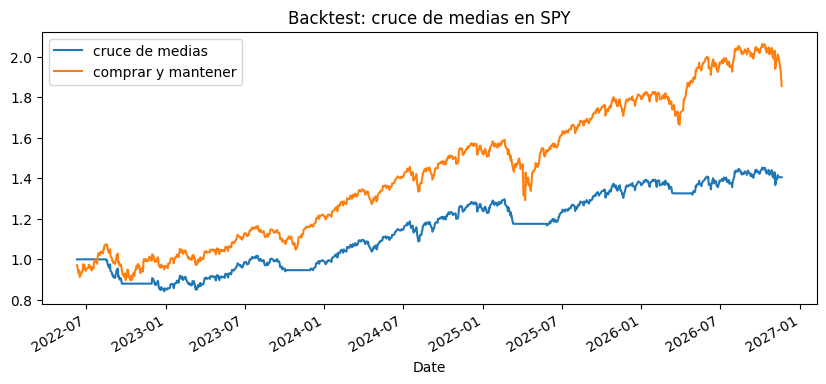

In [20]:
def metricas(r_diarios):
    """Metricas de desempeno a partir de retornos diarios simples."""
    r_diarios = r_diarios.dropna()
    anual = (1 + r_diarios).prod() ** (252 / len(r_diarios)) - 1
    vol = r_diarios.std() * np.sqrt(252)
    sharpe = r_diarios.mean() / r_diarios.std() * np.sqrt(252)
    equity = (1 + r_diarios).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()
    return pd.Series({"retorno anual": anual, "volatilidad": vol, "Sharpe": sharpe, "max drawdown": max_dd})

precio = df["SPY"]
rapida, lenta = precio.rolling(20).mean(), precio.rolling(100).mean()

senal = (rapida > lenta).astype(int)       # 1 = comprado, 0 = efectivo
posicion = senal.shift(1)                  # se opera al dia siguiente (evita look-ahead)
costo = 0.001                              # 0.1% por cada cambio de posicion

r_spy = ret["SPY"]
r_estrategia = posicion * r_spy - costo * posicion.diff().abs()
r_estrategia = r_estrategia.loc[lenta.dropna().index].dropna()
r_bh = r_spy.loc[r_estrategia.index]

print(pd.DataFrame({"estrategia": metricas(r_estrategia), "comprar y mantener": metricas(r_bh)}).round(3))

(1 + r_estrategia).cumprod().plot(label="cruce de medias")
(1 + r_bh).cumprod().plot(label="comprar y mantener")
plt.legend(); plt.title("Backtest: cruce de medias en SPY"); plt.show()

## 10. Pairs trading

Estrategia **market-neutral**: se opera la diferencia (spread) entre dos activos relacionados, no la direccion del mercado.

**Pasos:**

1. Elegir dos activos del mismo sector (ejemplo clasico: KO y PEP).
2. Probar **cointegracion** (test de Engle-Granger). Correlacion alta NO basta: dos series pueden estar correlacionadas y alejarse para siempre. Cointegradas significa que una combinacion lineal es estacionaria (el spread vuelve a su media).
3. Estimar el **hedge ratio** $\beta$ con regresion sobre log-precios: $\ln P_Y = \alpha + \beta\ln P_X + \text{spread}$.
4. Calcular el **z-score** del spread: $z = (\text{spread} - \text{media}_{60})/\text{desv}_{60}$.
5. Reglas: si $z > 2$ el spread esta alto, se vende Y y se compra X. Si $z < -2$ se hace lo contrario. Se cierra cuando $|z| < 0.5$.

**Para no hacer trampa:** $\beta$ se estima solo con la primera mitad de los datos y la estrategia se prueba en la segunda mitad.

Test de cointegracion (entrenamiento) p-valor: 0.151  -> no hay evidencia fuerte de cointegracion
beta = 1.100, alpha = 0.596


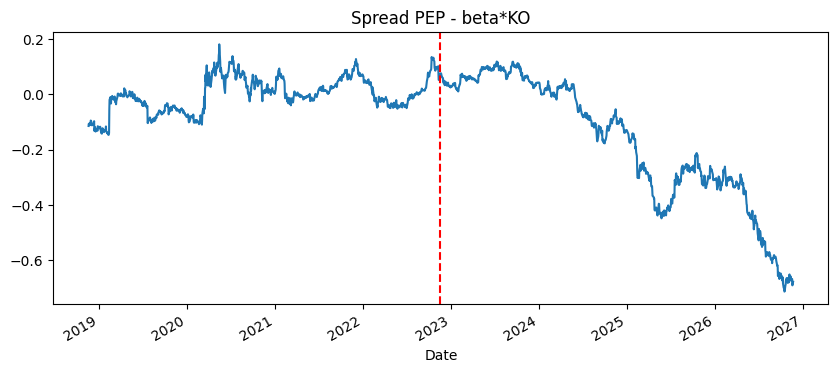

In [21]:
from statsmodels.tsa.stattools import coint

par = yf.download(["KO", "PEP"], period="8y", auto_adjust=True, progress=False)["Close"].dropna()
ly, lx = np.log(par["PEP"]), np.log(par["KO"])     # Y = PEP, X = KO

mitad = len(par) // 2
# Cointegracion solo con datos de entrenamiento
p_coint = coint(ly.iloc[:mitad], lx.iloc[:mitad])[1]
print(f"Test de cointegracion (entrenamiento) p-valor: {p_coint:.3f}  ->",
      "cointegrados" if p_coint < 0.05 else "no hay evidencia fuerte de cointegracion")

# Hedge ratio con regresion lineal (solo entrenamiento)
beta, alpha = np.polyfit(lx.iloc[:mitad], ly.iloc[:mitad], 1)
print(f"beta = {beta:.3f}, alpha = {alpha:.3f}")

spread = ly - beta * lx - alpha
z = (spread - spread.rolling(60).mean()) / spread.rolling(60).std()

spread.plot(title="Spread PEP - beta*KO"); plt.axvline(par.index[mitad], color="red", ls="--"); plt.show()

retorno anual   -0.067
volatilidad      0.062
Sharpe          -1.096
max drawdown    -0.282
dtype: float64
Numero de cambios de posicion en prueba: 28


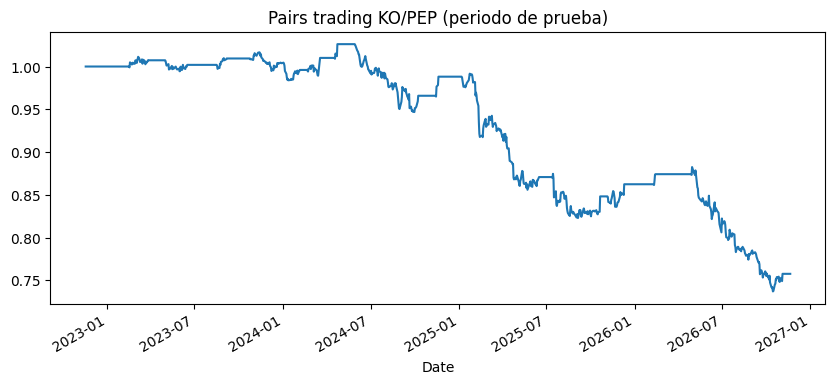

In [22]:
# Maquina de estados: -1 = corto en el spread, 0 = fuera, +1 = largo en el spread
estado = 0
pos = []
for zi in z:
    if np.isnan(zi):
        pos.append(0); continue
    if estado == 0:
        if zi > 2:    estado = -1
        elif zi < -2: estado = 1
    elif estado == 1 and zi > -0.5:
        estado = 0
    elif estado == -1 and zi < 0.5:
        estado = 0
    pos.append(estado)
pos = pd.Series(pos, index=z.index)

# Retorno del spread: largo Y y corto beta*X cuando pos = +1
rets = par.pct_change()
r_spread = rets["PEP"] - beta * rets["KO"]
exposicion = 1 + abs(beta)                              # capital bruto usado
r_par = pos.shift(1) * r_spread / exposicion            # se opera al dia siguiente
r_par = r_par - 0.001 * pos.diff().abs() / 1.0          # costo por cambio de posicion

prueba = r_par.iloc[mitad:].dropna()                    # solo la mitad de prueba
print(metricas(prueba).round(3))
print("Numero de cambios de posicion en prueba:", int(pos.iloc[mitad:].diff().abs().gt(0).sum()))

(1 + prueba).cumprod().plot(title="Pairs trading KO/PEP (periodo de prueba)"); plt.show()

Si el resultado es pobre o el test de cointegracion no es significativo, **es una ensenanza valida**: muchas parejas pierden la relacion con el tiempo. En la practica se escanean muchos pares y se vuelve a probar la cointegracion periodicamente.

## 11. Machine Learning

### 11.1 HMM (Hidden Markov Model): regimenes de mercado

El mercado alterna entre **regimenes** no observables (por ejemplo calma y crisis). Un HMM supone:

- Un estado oculto $S_t \in \{1,...,K\}$ que sigue una cadena de Markov con matriz de transicion $A$ ($A_{ij} = P(S_{t+1}=j \mid S_t=i)$).
- En cada estado los retornos tienen su propia distribucion normal (media y varianza propias).

El modelo se ajusta con el algoritmo EM y los estados se infieren con Viterbi. Aqui usamos 2 estados.

**Aviso:** ajustar y predecir sobre toda la muestra usa informacion futura. Sirve para **entender** los regimenes, no para operar directamente. Para operar se re-ajusta con una ventana que solo mira hacia atras.

Estado 0 (calma): media diaria 0.092%, vol diaria 0.744%, 69% del tiempo
Estado 1 (turbulento): media diaria -0.073%, vol diaria 1.622%, 31% del tiempo

Matriz de transicion (filas = estado actual):
            calma  turbulento
calma       0.991       0.009
turbulento  0.019       0.981


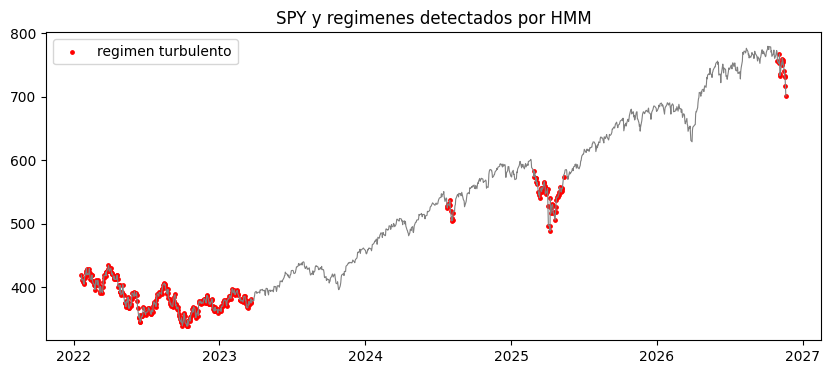

In [23]:
from hmmlearn.hmm import GaussianHMM

X = (lret["SPY"] * 100).values.reshape(-1, 1)
hmm = GaussianHMM(n_components=2, covariance_type="full", n_iter=200, random_state=42).fit(X)
estados = hmm.predict(X)

# Ordenar: estado 0 = baja volatilidad, estado 1 = alta volatilidad
vols = np.sqrt(hmm.covars_.flatten())
orden = np.argsort(vols)
mapa = {orden[0]: 0, orden[1]: 1}
estados = np.array([mapa[e] for e in estados])

for k, nombre in [(0, "calma"), (1, "turbulento")]:
    sel = X[estados == k, 0]
    print(f"Estado {k} ({nombre}): media diaria {sel.mean():.3f}%, vol diaria {sel.std():.3f}%, {len(sel)/len(X):.0%} del tiempo")

print("\nMatriz de transicion (filas = estado actual):")
A = hmm.transmat_[np.ix_(orden, orden)]
print(pd.DataFrame(A, index=["calma", "turbulento"], columns=["calma", "turbulento"]).round(3))

serie = df["SPY"].iloc[1:]
plt.plot(serie.index, serie.values, color="gray", lw=0.8)
plt.scatter(serie.index[estados == 1], serie.values[estados == 1], color="red", s=6, label="regimen turbulento")
plt.legend(); plt.title("SPY y regimenes detectados por HMM"); plt.show()

**Lectura:** la diagonal de la matriz de transicion es alta (por ejemplo 0.98), lo que indica que los regimenes son persistentes: si hoy estamos en calma, lo mas probable es seguir en calma.

### 11.2 SGD (descenso de gradiente estocastico): clasificar la direccion

Predecir si **manana** el SPY sube (1) o baja (0), con **regresion logistica entrenada por SGD** (`SGDClassifier(loss="log_loss")`).

El SGD actualiza los pesos del modelo con pequenos lotes de datos en cada paso, siguiendo la direccion contraria al gradiente de la funcion de perdida.

**Buenas practicas:**

- Las variables (features) usan solo informacion hasta hoy; el objetivo es el signo del retorno de manana.
- Division **temporal** (nunca aleatoria): primero el 70% para entrenar y el 30% final para probar.
- Escalar variables con `StandardScaler` (SGD es sensible a la escala).
- Comparar con la linea base: acertar siempre la clase mas frecuente.

Expectativa: la exactitud sera cercana a 50-55%. Eso es normal; mejorar eso es el verdadero reto.

In [24]:
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

r1 = ret["SPY"]
feat = pd.DataFrame({
    "r_t":      r1,
    "r_t-1":    r1.shift(1),
    "r_t-2":    r1.shift(2),
    "media_5":  r1.rolling(5).mean(),
    "vol_5":    r1.rolling(5).std(),
    "vol_20":   r1.rolling(20).std(),
    "mom_20":   df["SPY"].pct_change(20).reindex(r1.index),
})
objetivo = (r1.shift(-1) > 0).astype(int)      # 1 si manana sube

datos = feat.join(objetivo.rename("y")).dropna()
datos = datos.iloc[:-1]                         # la ultima fila no tiene "manana" real

corte = int(len(datos) * 0.7)
Xtr, ytr = datos.drop(columns="y").iloc[:corte], datos["y"].iloc[:corte]
Xte, yte = datos.drop(columns="y").iloc[corte:], datos["y"].iloc[corte:]

clf = make_pipeline(StandardScaler(), SGDClassifier(loss="log_loss", alpha=1e-3, random_state=42))
clf.fit(Xtr, ytr)

pred = clf.predict(Xte)
print(f"Exactitud en prueba: {(pred == yte).mean():.3f}")
print(f"Linea base (siempre la clase mas frecuente): {max(yte.mean(), 1 - yte.mean()):.3f}")

Exactitud en prueba: 0.490
Linea base (siempre la clase mas frecuente): 0.529


               modelo SGD  comprar y mantener
retorno anual      -0.058               0.132
volatilidad         0.109               0.131
Sharpe             -0.491               1.006
max drawdown       -0.173              -0.100


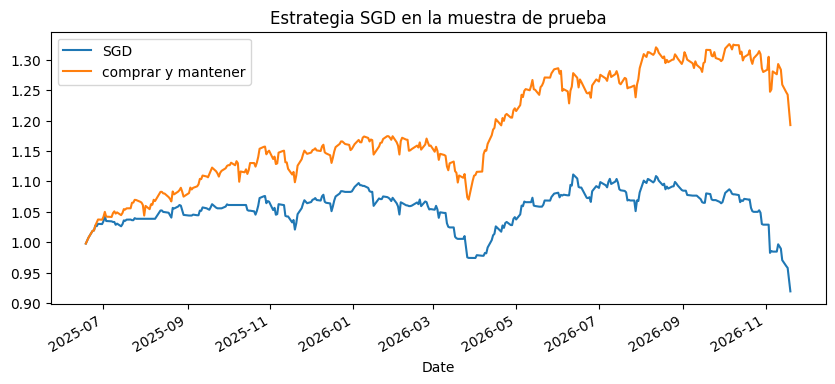

In [25]:
# Convertir las predicciones en una estrategia: comprado solo si el modelo predice subida
r_manana = r1.shift(-1).loc[Xte.index]
r_ml = pd.Series(pred, index=Xte.index) * r_manana - 0.001 * pd.Series(pred, index=Xte.index).diff().abs().fillna(0)

print(pd.DataFrame({"modelo SGD": metricas(r_ml), "comprar y mantener": metricas(r_manana)}).round(3))

(1 + r_ml).cumprod().plot(label="SGD")
(1 + r_manana).cumprod().plot(label="comprar y mantener")
plt.legend(); plt.title("Estrategia SGD en la muestra de prueba"); plt.show()

**Siguiente nivel (para practicar despues):**

- Validacion **walk-forward** con `TimeSeriesSplit` en lugar de una sola division.
- Combinar HMM y SGD: usar el regimen como variable del modelo, o operar solo en el regimen de calma.
- Mas variables (volumen, VIX, retornos de otros activos) y comparar con regresion logistica normal.

## 12. Paper trading

Operar con dinero **simulado** y precios reales antes de arriesgar capital. Valida que la estrategia funcione en tiempo real y revela problemas que el backtest no muestra (retrasos, ejecucion, datos).

En esta version el paper trading corre con un **simulador local** (`paper_trading/engine.py`) que no necesita llaves ni cuenta de broker. Aplica el cruce de medias 20/100 de la seccion 9 a todo el portafolio del notebook (META, NVDA, DBO, SPY, QQQ, CEG, SCHD), con capital inicial de 100,000 USD repartido en partes iguales, solo largo, deslizamiento de 5 pb y comision cero.

Reglas para evitar look-ahead: la senal se calcula con el cierre del dia $t$ y la orden se ejecuta al cierre del dia $t+1$. El estado (efectivo, posiciones, ordenes pendientes) se guarda en `paper_trading/data/` y cada corrida solo procesa los dias nuevos.

La primera vez que se ejecuta, los primeros 120 dias quedan marcados como `backfill` (reconstruidos con las mismas reglas, sin look-ahead) y desde la fecha de inicio quedan como `live`. Para comparar contra el backtest hay que mirar solo los dias `live`.

Para operar con un broker (Alpaca paper) se puede reemplazar la ejecucion del simulador por `TradingClient(KEY, SECRET, paper=True)`, con las llaves en `.env` fuera del notebook.

In [26]:
import subprocess, sys
from pathlib import Path
args = [sys.executable, "paper_trading/engine.py"]
if not Path("paper_trading/data/state.json").exists():
    args += ["--backfill", "120"]
res = subprocess.run(args, capture_output=True, text=True)
print(res.stdout)
if res.returncode:
    print(res.stderr[-1500:])

Sin dias nuevos. Ultima fecha procesada: 2026-11-20
Periodo: 2026-06-02 a 2026-11-20 (121 dias)
Capital final: 92,818.32 | Retorno: -7.18% | SPY buy&hold: -7.29%
Sharpe anualizado: -1.07 | Max drawdown: -10.86%
Posiciones: {'DBO': 728.8706, 'SCHD': 448.1648}
Ordenes pendientes para el proximo dia: {}



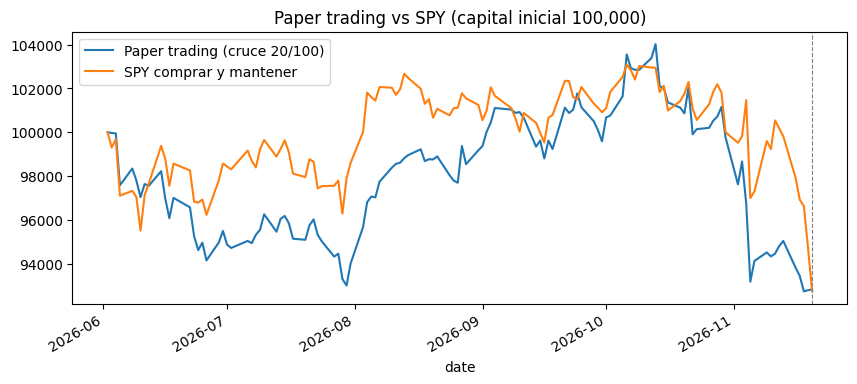

               paper trading    SPY
retorno anual         -0.145 -0.147
volatilidad            0.138  0.152
Sharpe                -1.067 -0.965
max drawdown          -0.109 -0.100


In [27]:
eq = pd.read_csv("paper_trading/data/equity.csv", parse_dates=["date"]).set_index("date")
bench = df["SPY"].reindex(eq.index)
curva = pd.DataFrame({"Paper trading (cruce 20/100)": eq["equity"], "SPY comprar y mantener": bench / bench.iloc[0] * eq["equity"].iloc[0]})
curva.plot(title="Paper trading vs SPY (capital inicial 100,000)")
plt.axvline(eq.index[eq["mode"] == "live"][0], color="gray", ls="--", lw=0.8)
plt.show()
print(pd.DataFrame({"paper trading": metricas(eq["equity"].pct_change().dropna()), "SPY": metricas(bench.pct_change().dropna())}).round(3))

In [28]:
operaciones = pd.read_csv("paper_trading/data/trades.csv")
operaciones["deslizamiento_%"] = ((operaciones["price"] / operaciones["ref_price"] - 1) * 100).round(3)
operaciones.tail(10)

,date,ticker,side,qty,price,ref_price,mode,deslizamiento_%
8,2026-08-12,META,SELL,23.5767,578.1043,578.3935,backfill,-0.05
9,2026-09-02,CEG,BUY,49.3048,289.7428,289.5980,backfill,0.05
10,2026-09-18,META,BUY,15.4914,665.5576,665.2250,backfill,0.05
11,2026-10-06,CEG,SELL,49.3048,299.7922,299.9422,backfill,-0.05
12,2026-10-13,CEG,BUY,48.3463,295.4869,295.3393,backfill,0.05
13,2026-11-05,QQQ,SELL,19.2273,646.7265,647.0500,backfill,-0.05
14,2026-11-06,NVDA,SELL,66.6413,186.5467,186.6400,backfill,-0.05
15,2026-11-06,CEG,SELL,48.3463,249.4443,249.5691,backfill,-0.05
16,2026-11-16,SPY,SELL,19.0270,739.5800,739.9500,backfill,-0.05
17,2026-11-17,META,SELL,15.4914,618.5606,618.8700,backfill,-0.05


### 12.1 Seguimiento diario

Para avanzar la simulacion un dia, basta ejecutar `python paper_trading/engine.py` despues del cierre del mercado. Se actualizan `data/*.csv` y el sitio estatico `docs/paper-trading/`. Registrar durante 1 a 3 meses antes de sacar conclusiones.

## Resumen y errores comunes

| Tema | Idea clave | Error tipico |
|---|---|---|
| Retornos | Simples para portafolio, log para series de tiempo | Mezclarlos al agregar activos |
| VaR | Percentil de perdidas; CVaR mide la cola | Aplicar percentil a todo el DataFrame junto |
| VaR parametrico | Asume normalidad | Ignorar colas pesadas (kurtosis) |
| Backtesting VaR | Contar excepciones y Kupiec | No validar el modelo |
| Optimizacion | Min varianza y Sharpe | Confiar en la media historica |
| ARIMA/SARIMA | Estacionariedad, AIC/BIC, diagnostico | Esperar prediccion de retornos diarios |
| GARCH | La volatilidad se agrupa y es predecible | Usar volatilidad constante en crisis |
| Montecarlo | Cholesky para correlacion | Olvidar la correlacion entre activos |
| Black-Scholes | Referencia de valor, paridad put-call | Creer que es una estrategia por si sola |
| Backtest | `shift(1)`, costos, muestra de prueba | Look-ahead bias, sobreajuste |
| Pairs trading | Cointegracion, no solo correlacion | Estimar beta con todos los datos |
| ML | Division temporal, linea base | Mezclar datos aleatoriamente |
| Paper trading | Validar en vivo antes de usar dinero real | Saltarse esta etapa |

Este notebook es material educativo, no asesoria financiera.